In [1]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Set professional plot style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14, 'xtick.labelsize': 10, 'ytick.labelsize': 10})

# Load dataset (handling potential naming/extension variations based on file list)
file_path = '/content/city_day_cleaned.csv.xls'
df = pd.read_csv(file_path)

# Convert Date to datetime if present
date_col = next((col for col in df.columns if 'date' in col.lower()), None)
if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')

# Identify AQI and City columns
aqi_col = next((col for col in df.columns if col.upper() == 'AQI'), None)
city_col = next((col for col in df.columns if 'city' in col.lower()), None)
bucket_col = next((col for col in df.columns if 'bucket' in col.lower() or 'category' in col.lower()), None)

# Identify available numerical pollutants from the standard list
possible_pollutants = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NO', 'NOx', 'NH3']
pollutants = [col for col in df.columns if col in possible_pollutants or col.upper() in possible_pollutants]

# Create directory to save figures
os.makedirs('/content/plots', exist_ok=True)
image_paths = []

### 1. Average AQI by City — Bar Chart

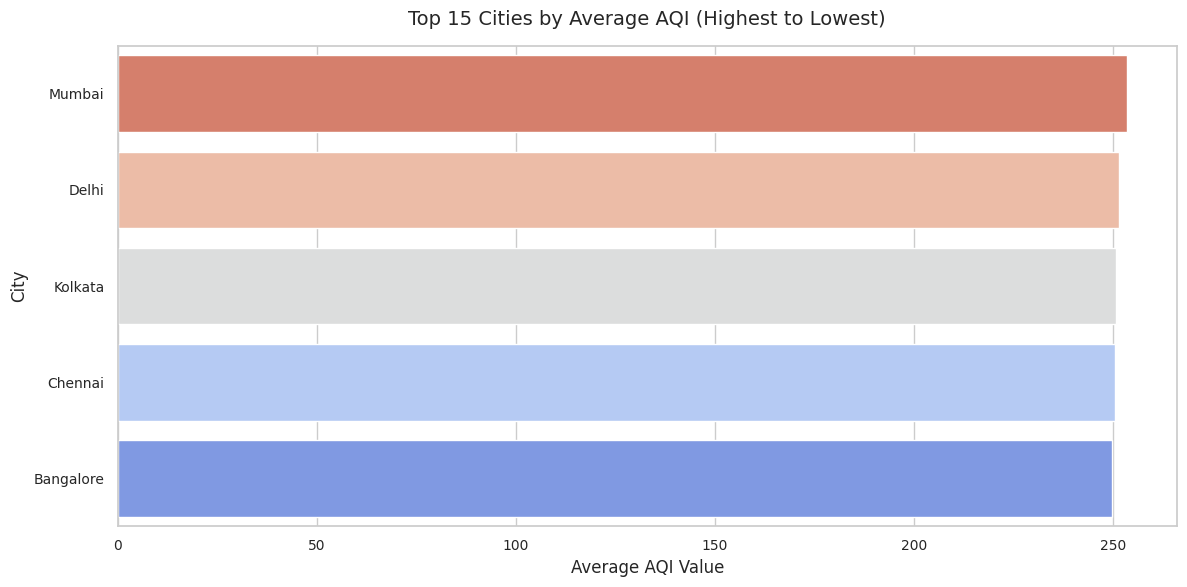

In [2]:
if aqi_col and city_col:
    plt.figure(figsize=(12, 6))
    city_aqi = df.groupby(city_col)[aqi_col].mean().sort_values(ascending=False).head(15)
    sns.barplot(x=city_aqi.values, y=city_aqi.index, palette="coolwarm_r", hue=city_aqi.index, legend=False)
    plt.title('Top 15 Cities by Average AQI (Highest to Lowest)', pad=15)
    plt.xlabel('Average AQI Value')
    plt.ylabel('City')
    plt.tight_layout()

    path = '/content/plots/1_avg_aqi_by_city.png'
    plt.savefig(path, dpi=300, bbox_inches='tight')
    image_paths.append(path)
    plt.show()
else:
    print("City or AQI columns missing for Graph 1.")

**Interpretation:** This bar chart highlights the cities with the highest average AQI values. Cities at the top exhibit critical levels of pollution, signaling regions where immediate environmental intervention is required, while lower values show relatively safer atmospheric standards.

### 2. AQI Trend Over Time — Line Chart

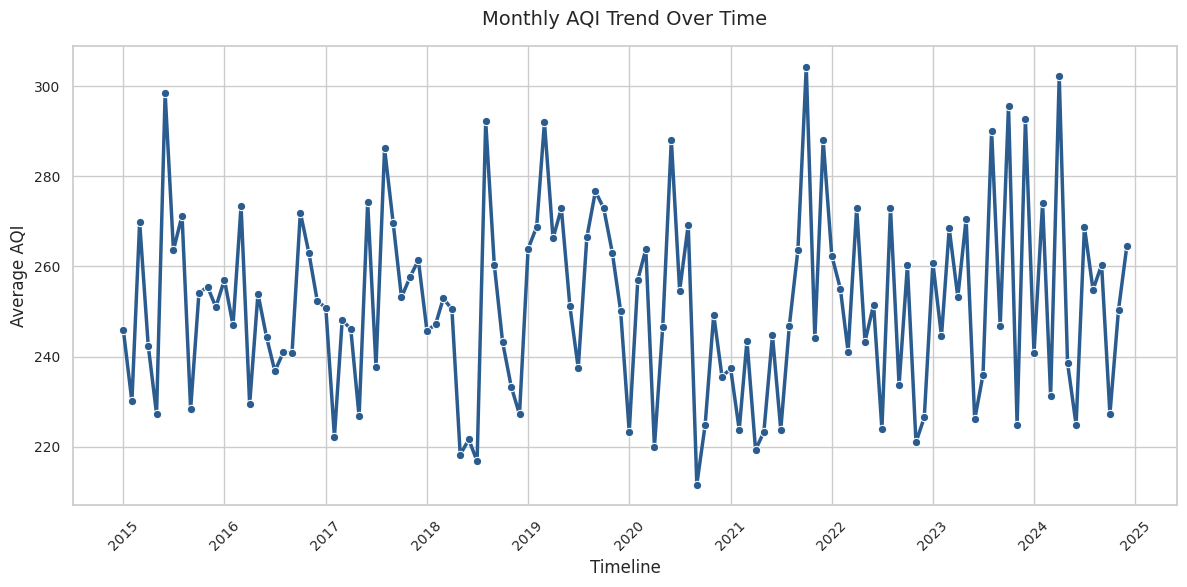

In [3]:
if aqi_col and date_col:
    plt.figure(figsize=(12, 6))
    # Grouping by month to show a smooth trend over time
    trend_df = df.groupby(df[date_col].dt.to_period('M'))[aqi_col].mean().reset_index()
    trend_df[date_col] = trend_df[date_col].dt.to_timestamp()

    sns.lineplot(data=trend_df, x=date_col, y=aqi_col, color='#2b5c8f', linewidth=2.5, marker='o')
    plt.title('Monthly AQI Trend Over Time', pad=15)
    plt.xlabel('Timeline')
    plt.ylabel('Average AQI')
    plt.xticks(rotation=45)
    plt.tight_layout()

    path = '/content/plots/2_aqi_trend_over_time.png'
    plt.savefig(path, dpi=300, bbox_inches='tight')
    image_paths.append(path)
    plt.show()
else:
    print("Date or AQI columns missing for Graph 2.")

**Interpretation:** The line graph reveals structural seasonal variations in AQI levels over the recorded timeline. Periodic peaks indicate recurring high pollution intervals (such as winter months or specific dry seasons), contrasted by valley periods showing relative recovery.

### 3. Average Pollutant Levels — Bar Chart

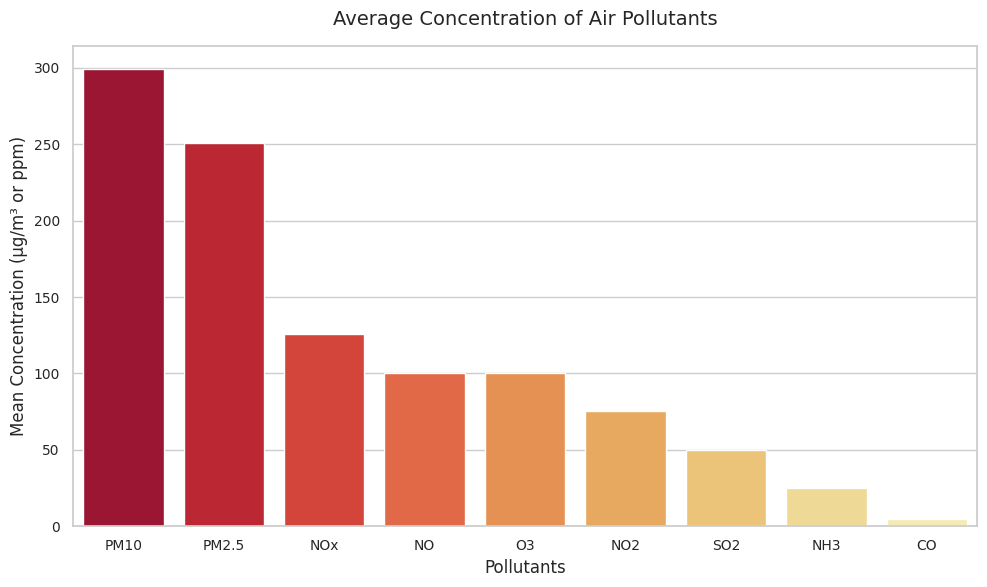

In [4]:
if pollutants:
    plt.figure(figsize=(10, 6))
    avg_pollutants = df[pollutants].mean().sort_values(ascending=False)
    sns.barplot(x=avg_pollutants.index, y=avg_pollutants.values, palette="YlOrRd_r", hue=avg_pollutants.index, legend=False)
    plt.title('Average Concentration of Air Pollutants', pad=15)
    plt.xlabel('Pollutants')
    plt.ylabel('Mean Concentration (μg/m³ or ppm)')
    plt.tight_layout()

    path = '/content/plots/3_avg_pollutant_levels.png'
    plt.savefig(path, dpi=300, bbox_inches='tight')
    image_paths.append(path)
    plt.show()
else:
    print("No relevant pollutant columns found for Graph 3.")

**Interpretation:** This comparative graph shows the mean concentrations of primary atmospheric pollutants. Particulate matters (like PM10 or PM2.5) typically dominate standard concentrations, indicating their major role as key contributors to air toxicity relative to gaseous pollutants.

### 4. AQI Distribution — Histogram

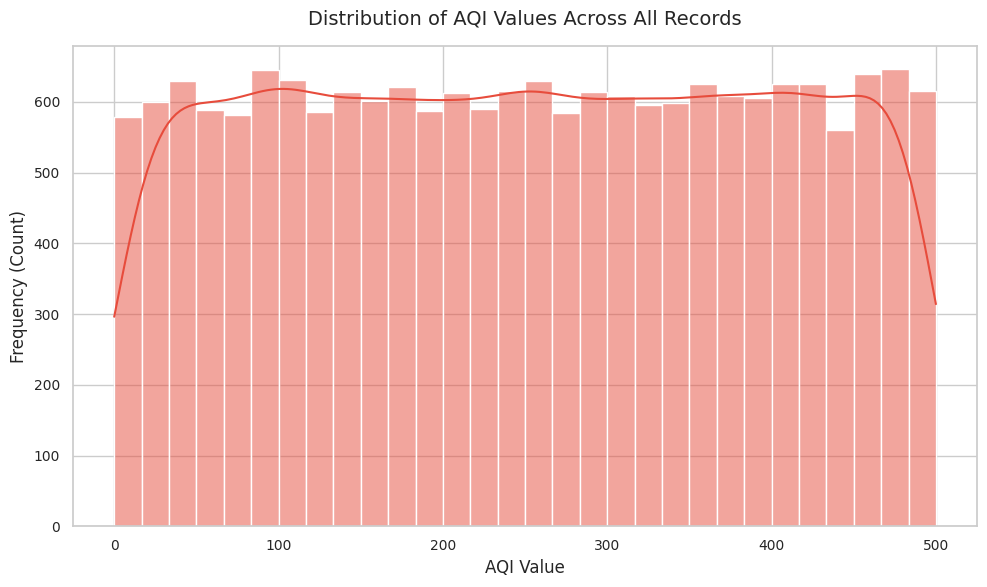

In [5]:
if aqi_col:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[aqi_col].dropna(), bins=30, kde=True, color='#e74c3c')
    plt.title('Distribution of AQI Values Across All Records', pad=15)
    plt.xlabel('AQI Value')
    plt.ylabel('Frequency (Count)')
    plt.tight_layout()

    path = '/content/plots/4_aqi_distribution.png'
    plt.savefig(path, dpi=300, bbox_inches='tight')
    image_paths.append(path)
    plt.show()
else:
    print("AQI column missing for Graph 4.")

**Interpretation:** The histogram showcases the frequency pattern of AQI. A right-skewed layout is standard for environmental datasets, signifying that while most days enjoy moderate to satisfactory air quality, severe extreme pollution incidents remain a recurring threat.

### 5. Pollutant Correlation — Heatmap

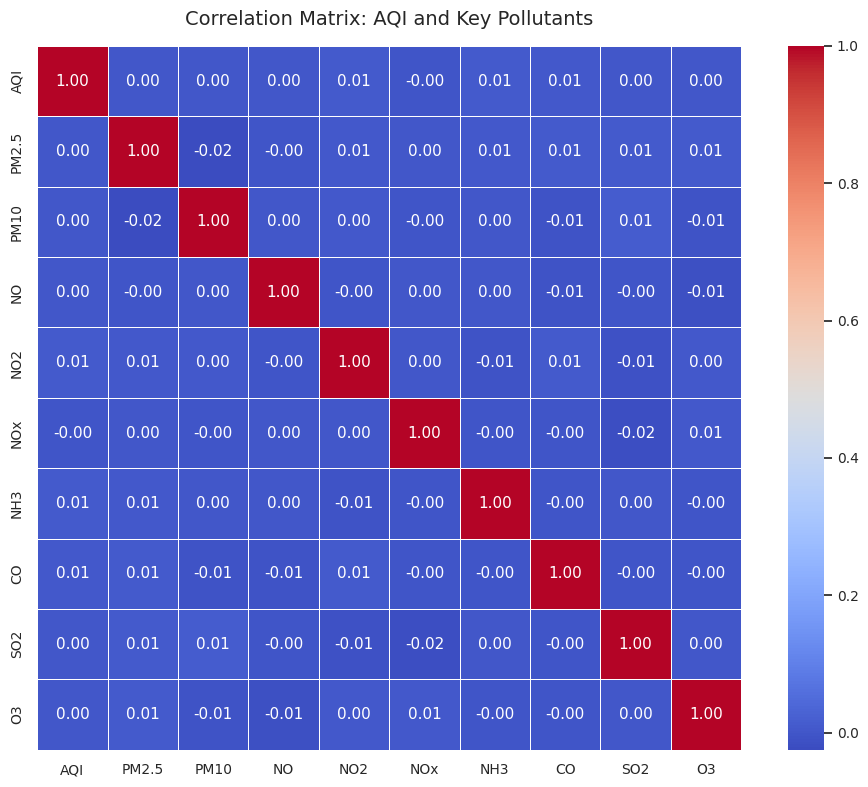

In [6]:
corr_cols = [col for col in [aqi_col] + pollutants if col is not None]
if len(corr_cols) > 1:
    plt.figure(figsize=(10, 8))
    correlation_matrix = df[corr_cols].corr()
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True, linewidths=0.5)
    plt.title('Correlation Matrix: AQI and Key Pollutants', pad=15)
    plt.tight_layout()

    path = '/content/plots/5_pollutant_correlation.png'
    plt.savefig(path, dpi=300, bbox_inches='tight')
    image_paths.append(path)
    plt.show()
else:
    print("Insufficient columns available to plot a correlation matrix for Graph 5.")

**Interpretation:** This correlation map demonstrates how closely each pollutant matches AQI fluctuations. High positive coefficients (approaching +1.0) suggest that specific pollutants are primary drivers behind deteriorating regional air index metrics.

### 6. AQI Category Distribution — Pie Chart

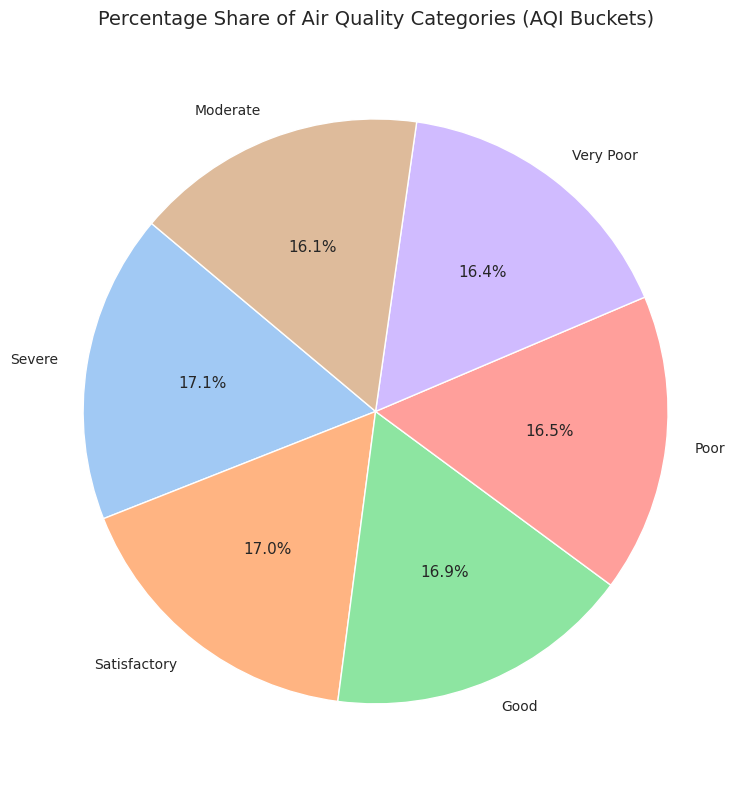

In [7]:
if bucket_col:
    plt.figure(figsize=(8, 8))
    category_counts = df[bucket_col].value_counts()
    colors = sns.color_palette('pastel')[0:len(category_counts)]

    plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', startangle=140, colors=colors,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1})
    plt.title('Percentage Share of Air Quality Categories (AQI Buckets)', pad=15)
    plt.tight_layout()

    path = '/content/plots/6_aqi_category_distribution.png'
    plt.savefig(path, dpi=300, bbox_inches='tight')
    image_paths.append(path)
    plt.show()
else:
    print("AQI Category/Bucket column is missing for Graph 6.")

**Interpretation:** The pie chart profiles the macro air quality categories. It quickly exposes what proportion of typical days fall into acceptable criteria ('Good', 'Satisfactory', 'Moderate') versus critical hazard levels ('Poor', 'Severe').

### Save & Download the Graphs together in a ZIP File

In [8]:
# ZIP all saved figures together
zip_path = '/content/air_quality_plots.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files_list in os.walk('/content/plots'):
        for file in files_list:
            zipf.write(os.path.join(root, file), file)

print(f"Successfully packaged all graphs into '{zip_path}'.")

# Trigger prompt to download the zip file directly
files.download(zip_path)

Successfully packaged all graphs into '/content/air_quality_plots.zip'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>